<a href="https://colab.research.google.com/github/romanotancredi/equity-investment-research-portfolio/blob/main/05_brinson_performance_attribution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Phase 5 — Historical Benchmark-Relative Performance Attribution

## Investment Objective

Evaluate the sources of active performance for a hypothetical
global equity portfolio relative to the Vanguard Total World
Stock ETF (VT), using historical benchmark regional allocations
rather than fixed hypothetical weights.

The analysis aims to distinguish the impact of regional
allocation decisions from differences in regional investment
returns.

## Portfolio & Benchmark

**Portfolio Allocation**
- US Equities (VTI): 60%
- Developed Markets ex-US (VEA): 30%
- Emerging Markets (VWO): 10%

**Benchmark:** Vanguard Total World Stock ETF (VT)

**Observation Period:** January 2020 – October 2026

**Portfolio Rebalancing:** Daily to constant target weights

## Methodology

The analysis applies a Brinson-Fachler attribution framework
using historical regional benchmark weights derived from
VT holdings disclosures.

The methodology includes:

1. **Historical Benchmark Weights**
   - Retrieve historical VT country allocations.
   - Aggregate country exposures into US, developed ex-US,
     and emerging markets.
   - Calculate regional active weights over time.

2. **Regional Allocation Effect**
   - Measure the impact of portfolio regional overweights
     and underweights relative to VT.
   - Assess whether regional positioning contributed
     positively or negatively to active performance.

3. **Selection & Interaction Effects**
   - Compare portfolio regional returns with corresponding
     benchmark regional returns where suitable data exist.
   - Calculate selection and interaction effects without
     introducing hypothetical investment returns.

4. **Multi-Period Attribution**
   - Calculate attribution effects using consistent
     return and weight observation periods.
   - Link contributions across periods and reconcile
     them with compounded portfolio-relative returns.

5. **Investment Interpretation**
   - Identify the regional decisions associated with
     historical outperformance and underperformance.
   - Evaluate the stability of attribution effects
     across different market environments.

## Data Sources

- Yahoo Finance: Historical adjusted ETF prices
  for VTI, VEA, VWO and VT.
- Historical VT holdings disclosures: Regional benchmark
  allocations derived from country-level holdings.
- Regional benchmark return proxies, subject to
  data availability and classification consistency.

## Methodological Limitations

Historical holdings observations may be less frequent
than daily portfolio returns and require an explicit
weight-alignment methodology.

Regional ETF returns may differ from the returns of
VT's underlying regional constituents.

Selection and interaction effects will only be reported
where distinct, comparable regional return series are
available. Any unexplained benchmark reconstruction
difference will be disclosed separately.

Therefore, the results should be interpreted as
benchmark-relative attribution estimates rather than
a complete security-level attribution of VT.

## Expected Outputs

- Historical portfolio and benchmark regional weights.
- Regional allocation, selection and interaction effects.
- Annual attribution charts by region and effect.
- Reconciliation against actual VT-relative performance.
- Investment conclusions identifying the primary
  sources of historical active returns.


In [22]:

# ---------------------------------------------------------
# PHASE 5 - STEP 1: LOAD HISTORICAL VT COUNTRY WEIGHTS
# ---------------------------------------------------------

import pandas as pd
import requests

# Historical country allocations reconstructed from
# VT's SEC Form N-PORT holdings disclosures.
#
# Source: The Mulden
# Underlying source: SEC N-PORT filings
#
# These are historical holdings observations,
# not daily benchmark weights.

vt_weights_url = (
    "https://themulden.com/data/country-weights/VT.json"
)

# Request the historical dataset.
response = requests.get(vt_weights_url, timeout=30)
response.raise_for_status()

# Parse the JSON response.
vt_raw = response.json()

# Inspect its structure before transforming the data.
# This avoids assuming a format that may not match
# the source's actual JSON schema.

print("Data type:", type(vt_raw).__name__)

if isinstance(vt_raw, dict):
    print("Top-level keys:", list(vt_raw.keys())[:15])

    for key, value in list(vt_raw.items())[:3]:
        print(f"\n{key}:")
        print(str(value)[:700])

elif isinstance(vt_raw, list):
    print("Number of records:", len(vt_raw))
    print("First record:")
    print(str(vt_raw[0])[:1500])

Data type: dict
Top-level keys: ['ticker', 'name', 'definition', 'generatedAt', 'periods']

ticker:
VT

name:
VANGUARD TOTAL WORLD STOCK INDEX FUND

definition:
ex-collateral-v2


In [14]:

# ---------------------------------------------------------
# PHASE 5 - STEP 2A: EXTRACT HISTORICAL VT COUNTRY WEIGHTS
# ---------------------------------------------------------

# Each key in "periods" represents a reporting date.
# Each value contains the country allocations and metadata.

records = []

for date, data in vt_raw["periods"].items():

    records.append({
        "Date": pd.to_datetime(date),
        "FiledDate": pd.to_datetime(data["filedDate"]),
        "byCountry": data["byCountry"]
    })

# Convert the records into a DataFrame.
vt_history = pd.DataFrame(records).sort_values("Date")

# Check the historical observations.
print(f"Number of reporting periods: {len(vt_history)}")
print(f"First observation: {vt_history['Date'].min().date()}")
print(f"Last observation: {vt_history['Date'].max().date()}")

display(vt_history.head())

Number of reporting periods: 27
First observation: 2019-10-31
Last observation: 2026-04-30


,Date,FiledDate,byCountry
0,2019-10-31,2019-12-30,"{'US': 52.17, 'JP': 7.76, 'GB': 4.82, 'CA': 3...."
1,2020-01-31,2020-03-31,"{'US': 53.09, 'JP': 7.35, 'GB': 4.72, 'CA': 3...."
2,2020-04-30,2020-06-29,"{'US': 58.47, 'JP': 7.49, 'GB': 4.8, 'HK': 3.6..."
3,2020-07-31,2020-09-29,"{'US': 58.76, 'JP': 6.96, 'GB': 4.45, 'HK': 3...."
4,2020-10-31,2020-12-29,"{'US': 59.07, 'JP': 7.34, 'GB': 4.18, 'HK': 3...."


In [23]:

# ---------------------------------------------------------
# PHASE 5 - STEP 2B: HISTORICAL VT REGIONAL ALLOCATIONS
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define the developed markets ex-US classification.
# The classification follows the FTSE framework,
# which is relevant for the Vanguard ETFs used.
#
# South Korea (KR) and Poland (PL) are developed
# markets under FTSE, unlike MSCI.

developed_ex_us = {
    "JP", "GB", "CA", "CH", "FR", "DE",
    "AU", "NL", "KR", "TW_PLACEHOLDER",
    "IE", "HK", "SE", "ES", "IT",
    "DK", "SG", "FI", "BE", "PL",
    "NO", "IL", "NZ", "AT", "PT"
}

# Remove the placeholder: Taiwan belongs to EM.
developed_ex_us.remove("TW_PLACEHOLDER")

# Define emerging-market countries.
# Greece was upgraded by FTSE in September 2026;
# we handle that separately in classify_region().

emerging_markets = {
    "TW", "CN", "IN", "BR", "ZA", "RU",
    "TH", "MX", "MY", "ID", "SA", "PH",
    "QA", "AE", "KW", "TR", "CO", "CL",
    "HU", "EG", "CZ", "PK", "PE"
}


def classify_region(country, date):
    """
    Map reported country codes into the portfolio's
    three regional categories.

    Unrecognised incorporation jurisdictions remain
    Unclassified rather than being assigned arbitrarily.
    """

    if country == "US":
        return "VTI"

    # FTSE reclassified Greece to developed status
    # effective 21 September 2026.
    if country == "GR":
        return "VEA" if date >= pd.Timestamp("2026-09-21") else "VWO"

    if country in developed_ex_us:
        return "VEA"

    if country in emerging_markets:
        return "VWO"

    return "Unclassified"


# Convert the historical country-weight dictionaries
# into a long-format DataFrame.

rows = []

for _, observation in vt_history.iterrows():

    date = observation["Date"]
    filed_date = observation["FiledDate"]

    for country, weight in observation["byCountry"].items():

        rows.append({
            "Date": date,
            "FiledDate": filed_date,
            "Country": country,
            "Region": classify_region(country, date),
            "Weight": float(weight) / 100
        })

country_data = pd.DataFrame(rows)

# Aggregate country weights into regional exposures.
vt_regional_weights = (
    country_data
    .groupby(["Date", "Region"])["Weight"]
    .sum()
    .unstack(fill_value=0)
    .sort_index()
)

# Ensure the same region columns are always present.
regions = ["VTI", "VEA", "VWO"]

vt_regional_weights = vt_regional_weights.reindex(
    columns=regions + ["Unclassified"],
    fill_value=0
)

# Check the reported total weight at every date.
# Small differences from 100% may reflect rounding
# or source-specific accounting conventions.

vt_regional_weights["Total"] = (
    vt_regional_weights.sum(axis=1)
)

print("Historical VT Regional Weights (%):")
display((vt_regional_weights * 100).round(2))

# Identify the largest unclassified country exposures.
# This is an essential validation step before attribution.

unclassified_exposures = (
    country_data[country_data["Region"] == "Unclassified"]
    .groupby("Country")["Weight"]
    .agg(["mean", "max"])
    .sort_values("mean", ascending=False)
    * 100
)

print("Largest Unclassified Country Exposures (%):")
display(unclassified_exposures.head(15).round(2))

print(
    "Average unclassified weight:",
    f"{vt_regional_weights['Unclassified'].mean():.2%}"
)

Historical VT Regional Weights (%):


Region,VTI,VEA,VWO,Unclassified,Total
Date,,,,,
2019-10-31,52.17,36.04,8.07,3.69,99.97
2020-01-31,53.09,35.07,7.69,4.13,99.98
2020-04-30,58.47,35.07,5.79,0.69,100.02
2020-07-31,58.76,34.59,6.25,0.40,100.00
2020-10-31,59.07,34.01,6.33,0.59,100.00
2021-01-31,58.34,34.36,6.52,0.75,99.97
2021-04-30,55.58,28.67,8.43,7.32,100.00
2021-07-31,58.98,32.24,8.72,0.04,99.98
2021-10-31,61.65,31.54,6.73,0.07,99.99


Largest Unclassified Country Exposures (%):


,mean,max
Country,,
KY,1.46,2.29
XX,0.55,7.29
BM,0.54,0.55
JE,0.30,0.30
LU,0.09,0.15
CW,0.08,0.08
LR,0.03,0.04
PA,0.03,0.03
OTHER,0.02,0.04


Average unclassified weight: 0.69%


Historical Regional Active Weights (pp):


Region,VTI,VEA,VWO
Date,,,
2019-10-31,7.83,-6.04,1.93
2020-01-31,6.91,-5.07,2.31
2020-04-30,1.53,-5.07,4.21
2020-07-31,1.24,-4.59,3.75
2020-10-31,0.93,-4.01,3.67
2021-01-31,1.66,-4.36,3.48
2021-04-30,4.42,1.33,1.57
2021-07-31,1.02,-2.24,1.28
2021-10-31,-1.65,-1.54,3.27


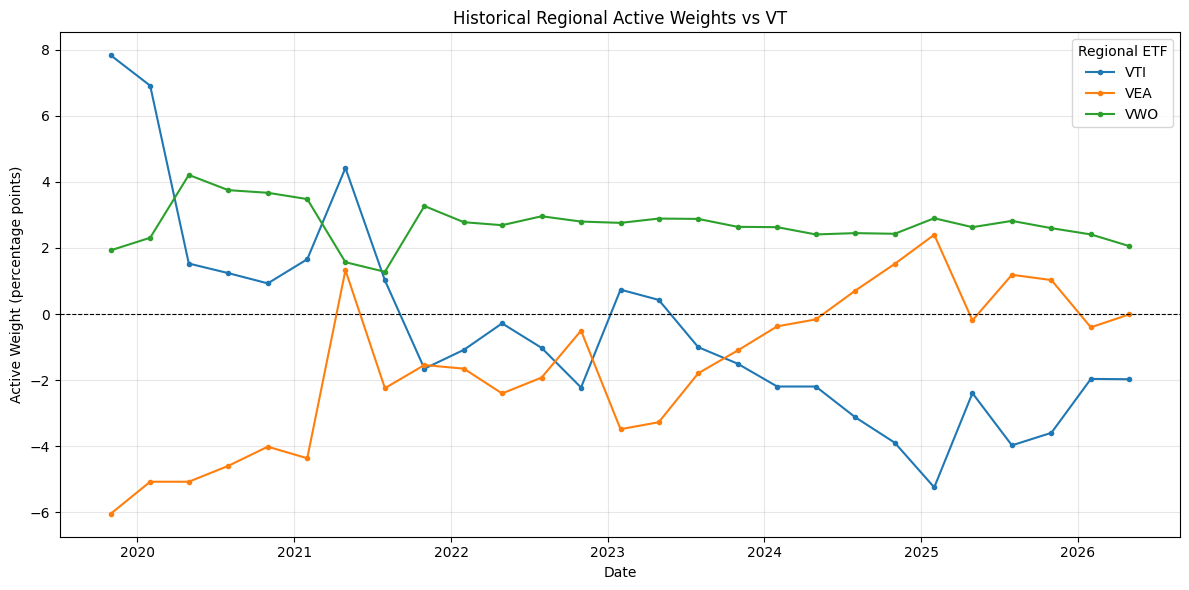

Average Historical Regional Allocations:


,Portfolio (%),VT Benchmark (%),Active Weight (pp)
VTI,60.0,60.46,-0.46
VEA,30.0,31.55,-1.55
VWO,10.0,7.29,2.71


Average unclassified VT exposure: 0.69%


In [24]:

# ---------------------------------------------------------
# PHASE 5 - STEP 2C: HISTORICAL ACTIVE REGIONAL WEIGHTS
# ---------------------------------------------------------

# Define the portfolio's constant target allocations.
portfolio_weights = pd.Series({
    "VTI": 0.60,  # US equities
    "VEA": 0.30,  # Developed markets ex-US
    "VWO": 0.10   # Emerging markets
})

# Extract VT's historical regional allocations.
benchmark_regional_weights = (
    vt_regional_weights[["VTI", "VEA", "VWO"]].copy()
)

# Calculate active weights for each historical date.
#
# Active Weight = Portfolio Weight - Benchmark Weight
#
# Positive value = Portfolio overweight
# Negative value = Portfolio underweight

active_weights = (
    benchmark_regional_weights.rsub(portfolio_weights)
)

# Convert weights into percentage points for display.
active_weights_pct = active_weights * 100

print("Historical Regional Active Weights (pp):")
display(active_weights_pct.round(2))

# ---------------------------------------------------------
# VISUALISATION: HISTORICAL ACTIVE REGIONAL WEIGHTS
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

# Plot each region's active weight over time.
for region in active_weights_pct.columns:

    ax.plot(
        active_weights_pct.index,
        active_weights_pct[region],
        marker="o",
        markersize=3,
        label=region
    )

# Add a zero line identifying neutral positioning.
ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=0.8
)

ax.set_title("Historical Regional Active Weights vs VT")
ax.set_xlabel("Date")
ax.set_ylabel("Active Weight (percentage points)")

ax.legend(title="Regional ETF")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# SUMMARY: AVERAGE HISTORICAL REGIONAL EXPOSURES
# ---------------------------------------------------------

summary_weights = pd.DataFrame({
    "Portfolio (%)": portfolio_weights * 100,
    "VT Benchmark (%)": benchmark_regional_weights.mean() * 100,
    "Active Weight (pp)": active_weights.mean() * 100
})

print("Average Historical Regional Allocations:")
display(summary_weights.round(2))

# Report how much VT remains unclassified.
print(
    f"Average unclassified VT exposure: "
    f"{vt_regional_weights['Unclassified'].mean():.2%}"
)

In [25]:

# Check the maximum unclassified exposure and total coverage.

print(
    "Maximum unclassified exposure:",
    f"{vt_regional_weights['Unclassified'].max():.2%}"
)

print(
    "Minimum total reported weight:",
    f"{vt_regional_weights['Total'].min():.2%}"
)

print(
    "Maximum total reported weight:",
    f"{vt_regional_weights['Total'].max():.2%}"
)


# ---------------------------------------------------------
# PHASE 5 - STEP 2D: INVESTIGATE UNCLASSIFIED EXPOSURES
# ---------------------------------------------------------

# Identify the date with the highest unclassified weight.
max_date = vt_regional_weights["Unclassified"].idxmax()

print("Highest unclassified exposure:")
print("Date:", max_date.date())
print(
    "Weight:",
    f"{vt_regional_weights.loc[max_date, 'Unclassified']:.2%}"
)

# Identify the countries responsible at that date.
unclassified_details = country_data[
    (country_data["Date"] == max_date)
    & (country_data["Region"] == "Unclassified")
].copy()

# Sort from largest to smallest.
unclassified_details = unclassified_details.sort_values(
    "Weight",
    ascending=False
)

# Display weights in percentage terms.
unclassified_details["Weight (%)"] = (
    unclassified_details["Weight"] * 100
)

display(
    unclassified_details[
        ["Country", "Weight (%)"]
    ].head(15)
)

# ---------------------------------------------------------
# PHASE 5 - STEP 2E: VALIDATE UNCLASSIFIED EXPOSURE
# ---------------------------------------------------------

# Display VT regional weights around the anomalous quarter.
# All values are shown as percentages.

display(
    (
        vt_regional_weights.loc[
            "2020-10-01":"2021-10-31",
            ["VTI", "VEA", "VWO", "Unclassified", "Total"]
        ] * 100
    ).round(2)
)

# Identify all dates with unclassified exposure above 1%.
problem_dates = vt_regional_weights[
    vt_regional_weights["Unclassified"] > 0.01
]

print("Reporting periods with >1% unclassified exposure:")
display((problem_dates * 100).round(2))



# ---------------------------------------------------------
# PHASE 5 - STEP 2F: BENCHMARK DATA QUALITY CONTROL
# ---------------------------------------------------------

# Set the maximum acceptable unclassified exposure
# to 1% of total benchmark holdings.

max_unclassified = 0.01

# Identify reliable and unreliable reporting periods.
valid_observations = (
    vt_regional_weights["Unclassified"] <= max_unclassified
)

# Retain the original historical data unchanged.
vt_weights_validated = vt_regional_weights.copy()

# Mark the regional weights as missing where the
# unclassified exposure exceeds our threshold.
#
# IMPORTANT:
# We are not setting those regional exposures to zero.
# We are identifying observations that cannot be
# reliably classified.

vt_weights_validated.loc[
    ~valid_observations,
    ["VTI", "VEA", "VWO"]
] = np.nan

print("Excluded reporting periods:")
display(
    vt_regional_weights.loc[
        ~valid_observations,
        ["VTI", "VEA", "VWO", "Unclassified"]
    ].mul(100).round(2)
)

print(
    f"Valid reporting periods: "
    f"{valid_observations.sum()} / {len(valid_observations)}"
)

Maximum unclassified exposure: 7.32%
Minimum total reported weight: 99.97%
Maximum total reported weight: 100.02%
Highest unclassified exposure:
Date: 2021-04-30
Weight: 7.32%


,Country,Weight (%)
319,XX,7.29
368,OTHER,0.02
366,AR,0.01


Region,VTI,VEA,VWO,Unclassified,Total
Date,,,,,
2020-10-31,59.07,34.01,6.33,0.59,100.00
2021-01-31,58.34,34.36,6.52,0.75,99.97
2021-04-30,55.58,28.67,8.43,7.32,100.00
2021-07-31,58.98,32.24,8.72,0.04,99.98
2021-10-31,61.65,31.54,6.73,0.07,99.99


Reporting periods with >1% unclassified exposure:


Region,VTI,VEA,VWO,Unclassified,Total
Date,,,,,
2019-10-31,52.17,36.04,8.07,3.69,99.97
2020-01-31,53.09,35.07,7.69,4.13,99.98
2021-04-30,55.58,28.67,8.43,7.32,100.00


Excluded reporting periods:


Region,VTI,VEA,VWO,Unclassified
Date,,,,
2019-10-31,52.17,36.04,8.07,3.69
2020-01-31,53.09,35.07,7.69,4.13
2021-04-30,55.58,28.67,8.43,7.32


Valid reporting periods: 24 / 27


In [26]:

# ---------------------------------------------------------
# PHASE 5 - STEP 3A: ALIGN VT WEIGHTS WITH DAILY RETURNS
# ---------------------------------------------------------

# Load the historical ETF prices used in previous phases.
url = (
    "https://raw.githubusercontent.com/romanotancredi/"
    "equity-investment-research-portfolio/refs/heads/main/"
    "01-equity-performance-and-risk/data/etf_prices.csv"
)

prices = pd.read_csv(
    url,
    index_col="Date",
    parse_dates=["Date"]
).sort_index()

# Calculate daily returns for all four ETFs.
daily_returns = prices.pct_change().dropna()

# Extract valid VT regional weights from Step 2F.
valid_weights = vt_weights_validated[
    ["VTI", "VEA", "VWO"]
].dropna().copy()

# Match each holdings observation to its filing date.
filing_dates = (
    vt_history
    .set_index("Date")["FiledDate"]
)

# Assign the filing date as the date on which each
# benchmark-weight observation becomes available.
valid_weights["AvailableDate"] = filing_dates.reindex(
    valid_weights.index
)

# Remove rows with missing filing dates.
valid_weights = valid_weights.dropna(subset=["AvailableDate"])

# Set the filing date as the index.
valid_weights = (
    valid_weights
    .set_index("AvailableDate")
    .sort_index()
)

# Ensure there are no duplicate availability dates.
valid_weights = valid_weights[
    ~valid_weights.index.duplicated(keep="last")
]

# Reindex the quarterly disclosures to daily trading dates.
#
# ffill() carries forward the most recently published
# valid benchmark-weight observation.
#
# Missing values before the first filing remain missing.

daily_benchmark_weights = (
    valid_weights
    .reindex(
        valid_weights.index.union(daily_returns.index)
    )
    .sort_index()
    .ffill()
    .reindex(daily_returns.index)
)

# Display the resulting daily benchmark weights.
print("Daily VT Regional Weights (%):")
display((daily_benchmark_weights.tail() * 100).round(2))

# Verify there is no missing benchmark data in the
# historical period we intend to analyse.
print(
    "Days without available benchmark weights:",
    daily_benchmark_weights.isna().any(axis=1).sum()
)

Daily VT Regional Weights (%):


Region,VTI,VEA,VWO
Date,,,
2026-10-26,61.97,30.01,7.94
2026-10-27,61.97,30.01,7.94
2026-10-28,61.97,30.01,7.94
2026-10-29,61.97,30.01,7.94
2026-10-30,61.97,30.01,7.94


Days without available benchmark weights: 122


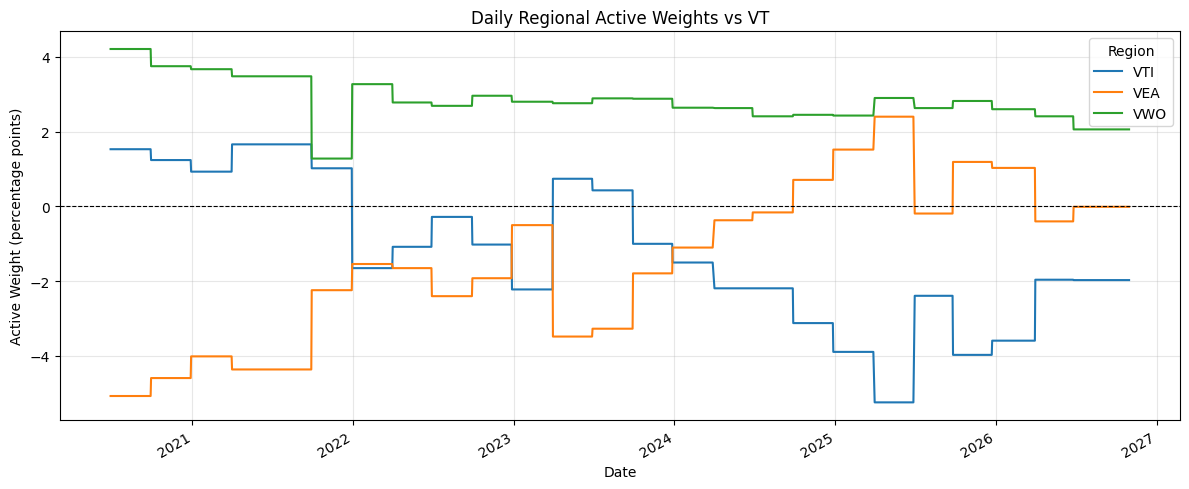

In [27]:

# ---------------------------------------------------------
# PHASE 5 - STEP 3B: DAILY ACTIVE REGIONAL ALLOCATIONS
# ---------------------------------------------------------

# Use the same portfolio allocation as previous phases.
portfolio_weights = pd.Series({
    "VTI": 0.60,
    "VEA": 0.30,
    "VWO": 0.10
})

# Calculate daily active weights.
#
# Positive = overweight relative to VT.
# Negative = underweight relative to VT.

daily_active_weights = (
    daily_benchmark_weights.rsub(portfolio_weights)
)

# Plot how active regional exposures changed over time.
ax = (daily_active_weights * 100).plot(
    figsize=(12, 5)
)

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)

ax.set_title("Daily Regional Active Weights vs VT")
ax.set_xlabel("Date")
ax.set_ylabel("Active Weight (percentage points)")
ax.legend(title="Region")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

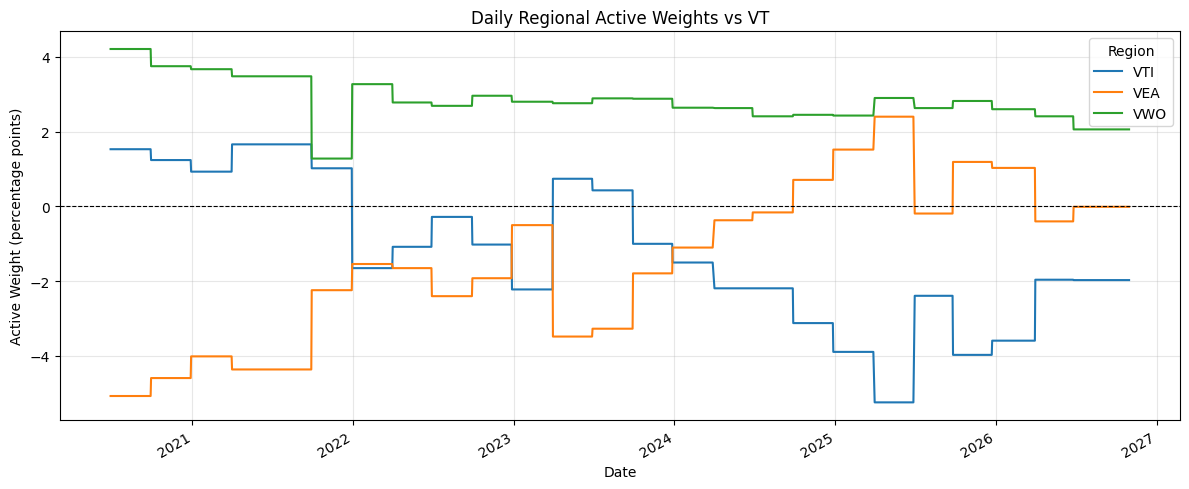

In [28]:

# ---------------------------------------------------------
# PHASE 5 - STEP 3B: DAILY ACTIVE REGIONAL ALLOCATIONS
# ---------------------------------------------------------

# Use the same portfolio allocation as previous phases.
portfolio_weights = pd.Series({
    "VTI": 0.60,
    "VEA": 0.30,
    "VWO": 0.10
})

# Calculate daily active weights.
#
# Positive = overweight relative to VT.
# Negative = underweight relative to VT.

daily_active_weights = (
    daily_benchmark_weights.rsub(portfolio_weights)
)

# Plot how active regional exposures changed over time.
ax = (daily_active_weights * 100).plot(
    figsize=(12, 5)
)

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)

ax.set_title("Daily Regional Active Weights vs VT")
ax.set_xlabel("Date")
ax.set_ylabel("Active Weight (percentage points)")
ax.legend(title="Region")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:

# ---------------------------------------------------------
# PHASE 5 - STEP 4A: DAILY ALLOCATION ATTRIBUTION
# ---------------------------------------------------------

regions = ["VTI", "VEA", "VWO"]

# Use dates where both returns and benchmark weights exist.
dates = daily_returns.index.intersection(
    daily_benchmark_weights.dropna().index
)

returns = daily_returns.loc[dates, regions + ["VT"]]
benchmark_weights = daily_benchmark_weights.loc[dates, regions].copy()

# Retain unclassified holdings as a residual benchmark sleeve.
# Minor rounding discrepancies are corrected by normalisation.
benchmark_weights["Unclassified"] = (
    1 - benchmark_weights[regions].sum(axis=1)
).clip(lower=0)

benchmark_weights = benchmark_weights.div(
    benchmark_weights.sum(axis=1), axis=0
)

# Portfolio target weights: 60% / 30% / 10%.
portfolio_weights = pd.Series({
    "VTI": 0.60,
    "VEA": 0.30,
    "VWO": 0.10,
    "Unclassified": 0.0
})

# Use VT's return as a proxy for the unclassified sleeve.
regional_returns = returns[regions].copy()
regional_returns["Unclassified"] = returns["VT"]

# Construct a regional proxy for the benchmark.
proxy_benchmark = (
    benchmark_weights * regional_returns
).sum(axis=1)

# Reconstruct the actual daily portfolio return.
portfolio_returns = returns[regions].dot(
    portfolio_weights[regions]
)

# Brinson-Fachler allocation effect by region.
#
# Allocation = (Portfolio Weight - Benchmark Weight)
#              * (Regional Return - Proxy Benchmark Return)

active_weights = portfolio_weights - benchmark_weights

allocation_effects = active_weights.mul(
    regional_returns.sub(proxy_benchmark, axis=0)
)

# Measure the difference between our reconstructed
# benchmark and actual VT returns.
#
# This is an approximation residual, not selection alpha.

benchmark_residual = proxy_benchmark - returns["VT"]

# Reconcile to the ACTUAL daily portfolio-minus-VT return.
daily_active_return = portfolio_returns - returns["VT"]

assert np.allclose(
    allocation_effects.sum(axis=1) + benchmark_residual,
    daily_active_return
)

print("Daily allocation effects (sample, pp):")
display((allocation_effects.head() * 100).round(4))

print(
    "Annualised benchmark proxy tracking error:",
    f"{benchmark_residual.std() * np.sqrt(252):.2%}"
)

Daily allocation effects (sample, pp):


Region,VTI,VEA,VWO,Unclassified
Date,,,,
2020-06-29,0.0037,0.0159,-0.0238,0.0002
2020-06-30,0.0099,0.0434,-0.0561,0.0012
2020-07-01,0.0006,0.0104,0.0336,-0.0009
2020-07-02,-0.0050,-0.0139,0.0690,-0.0012
2020-07-06,-0.0031,0.0050,0.1106,-0.0004


Annualised benchmark proxy tracking error: 0.84%


In [30]:

# ---------------------------------------------------------
# PHASE 5 - STEP 4B: COMPOUNDED ANNUAL ATTRIBUTION
# ---------------------------------------------------------

# Combine allocation effects and the benchmark residual.
daily_effects = allocation_effects.copy()
daily_effects["Benchmark Proxy Residual"] = benchmark_residual

annual_results = []

for year, group in daily_effects.groupby(daily_effects.index.year):

    # Daily portfolio and actual VT benchmark returns.
    rp = portfolio_returns.loc[group.index]
    rb = returns.loc[group.index, "VT"]

    # Compound benchmark returns before each day.
    previous_benchmark_growth = (
        (1 + rb).cumprod().shift(1).fillna(1.0)
    )

    # Compound portfolio returns after each day.
    future_portfolio_growth = (
        (1 + rp).iloc[::-1]
        .cumprod()
        .shift(1)
        .fillna(1.0)
        .iloc[::-1]
    )

    # Link daily contributions into annual contributions.
    linking_factor = (
        previous_benchmark_growth * future_portfolio_growth
    )

    linked_effects = group.mul(linking_factor, axis=0).sum()
    linked_effects.name = year

    annual_results.append(linked_effects)

annual_attribution = pd.DataFrame(annual_results)

# Compounded annual return difference.
annual_returns = pd.DataFrame({
    "Portfolio": portfolio_returns,
    "VT": returns["VT"]
})

annual_returns = (
    (1 + annual_returns)
    .groupby(annual_returns.index.year)
    .prod() - 1
)

annual_returns["Active Return"] = (
    annual_returns["Portfolio"] - annual_returns["VT"]
)

# Validate that all effects reconcile.
assert np.allclose(
    annual_attribution.sum(axis=1),
    annual_returns["Active Return"]
)

print("Annual linked attribution (percentage points):")
display((annual_attribution * 100).round(2))

print("Compounded annual returns (%):")
display((annual_returns * 100).round(2))

Annual linked attribution (percentage points):


Region,VTI,VEA,VWO,Unclassified,Benchmark Proxy Residual
2020,0.03,0.15,0.05,0.00,0.10
2021,0.09,0.24,-0.47,0.01,0.74
2022,0.03,-0.04,0.02,-0.00,0.06
2023,0.03,0.18,-0.37,0.00,0.08
2024,-0.19,-0.01,-0.14,-0.00,-0.09
2025,0.24,0.22,0.07,0.00,0.37
2026,0.03,0.05,-0.16,0.00,0.21


Compounded annual returns (%):


,Portfolio,VT,Active Return
Date,,,
2020,27.78,27.45,0.33
2021,18.87,18.27,0.60
2022,-17.93,-18.00,0.08
2023,21.94,22.02,-0.08
2024,16.07,16.49,-0.43
2025,23.33,22.43,0.89
2026,11.20,11.06,0.14


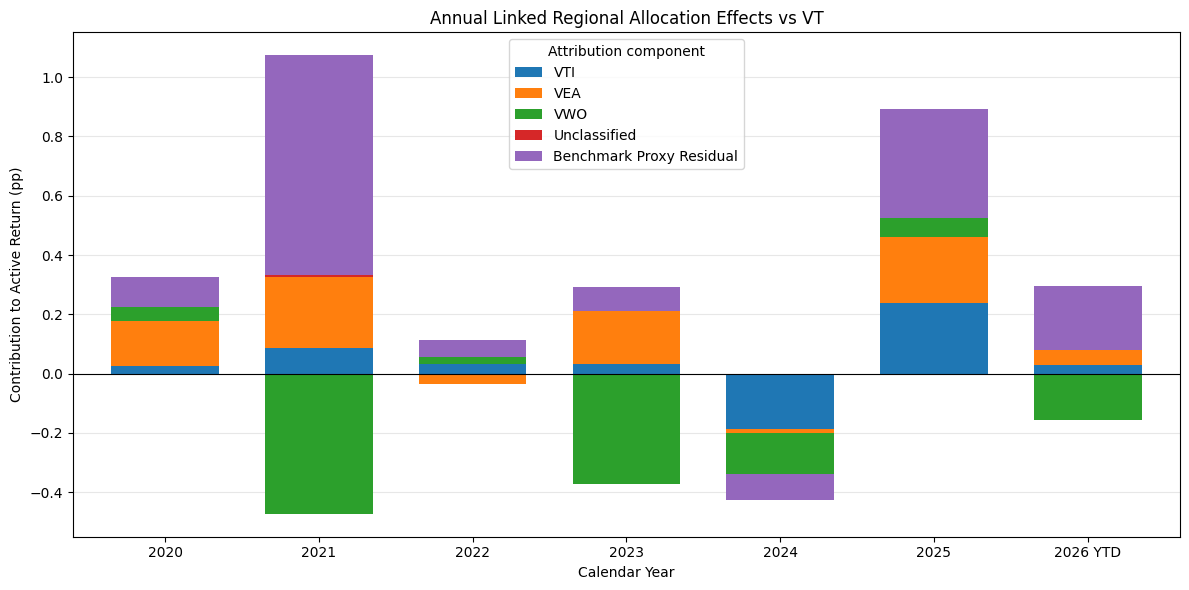

In [31]:

# ---------------------------------------------------------
# PHASE 5 - STEP 4C: ANNUAL ATTRIBUTION CHART
# ---------------------------------------------------------

chart_data = annual_attribution * 100

ax = chart_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.7
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set_title("Annual Linked Regional Allocation Effects vs VT")
ax.set_xlabel("Calendar Year")
ax.set_ylabel("Contribution to Active Return (pp)")

# Label the final incomplete year.
labels = [
    f"{year} YTD" if year == 2026 else str(year)
    for year in chart_data.index
]
ax.set_xticklabels(labels, rotation=0)

ax.legend(title="Attribution component")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## Key Findings & Investment Interpretation

### Historical Regional Allocation Effects

The Brinson-Fachler analysis incorporates historical VT regional
weights to estimate the impact of the portfolio's allocation
decisions relative to the benchmark.

Regional allocation effects varied across the observation period.
VTI and VEA contributed positively in 2025, while both VTI and
VWO detracted from relative performance in 2024.

In 2021, developed markets ex-US (VEA) generated a strong
positive allocation effect, partially offset by negative
contributions from emerging markets (VWO).

### Benchmark Reconstruction & Attribution Quality

The reconstructed regional benchmark exhibited annualised
tracking error of 0.84% relative to VT, compared with 0.89%
tracking error for the portfolio itself.

This indicates that benchmark approximation errors are
material relative to the portfolio's active risk.

The benchmark proxy residual was particularly significant
in 2021 and 2025, limiting our ability to attribute
outperformance exclusively to regional allocation decisions.

### Methodological Limitations

Historical benchmark weights were reconstructed from quarterly
VT holdings disclosures and aligned using filing availability
dates.

Three reporting periods exhibited unclassified country
exposures above 1%, including a peak of 7.32% in April 2021.
These observations were excluded from the benchmark-weight
estimation process.

Regional ETF returns were used as proxies for benchmark
regional returns. Consequently, selection and interaction
effects are zero by construction, and the model should be
interpreted as estimated allocation attribution rather than
a complete holdings-level Brinson analysis.

Geometrically linked contributions reconcile to compounded
annual portfolio-minus-VT returns after including the
benchmark reconstruction residual.

### Investment Implications

Historical US equity exposure contributed positively to
overall relative performance in Phase 4, but Phase 5
demonstrates that the impact of active regional allocation
varied materially across market environments.

The relatively large benchmark reconstruction residual
prevents definitive conclusions about the contribution of
regional allocation decisions to total outperformance.

### Conclusion

The analysis provides evidence of time-varying regional
allocation effects while highlighting the importance of
benchmark quality in institutional performance attribution.

Further refinement would require more granular benchmark
holdings, consistent regional classifications and distinct
regional benchmark return series to isolate allocation
and selection effects reliably.
